# Interacting fluorophores

How do interactions change individual fluorophore dynamics? We compare an
Atto643–Cy5 pair with and without transfer, inspect competing channels in a
three-molecule system, and explore matrix storage and mechanism-specific
orientation sampling.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fluopy import analysis as an
from fluopy import fluo_data as fd
from fluopy import fluorophores as fl
from fluopy import prediction as pr
from fluopy import simulation as si
from fluopy import transitions as tr

## Compare coupled and independent dynamics

Distinct names identify the two kinetic groups. constants supplies their
built-in data explicitly. The system assigns physical identities 0 and 1 in
list order. FRET is derived for all supported spectral channels in both
ordered directions, with rates set by the spectra and separation.

To isolate ordinary FRET in this tutorial, we retain only the s0 absorption
channel in each dye's data. Their other kinetic constants are unchanged.
Excited-state absorption and its additional transfer outcomes can be included
when modeling a system that requires them.

In [2]:
donor_data = replace(
    fd.atto643, absorption_spectra={"s0": fd.atto643.absorption_spectra["s0"]}
)
acceptor_data = replace(
    fd.cy5_dna, absorption_spectra={"s0": fd.cy5_dna.absorption_spectra["s0"]}
)
donor = fl.Fluorophore("donor", [0, 0], constants=donor_data)
acceptor = fl.Fluorophore("acceptor", [6, 0], constants=acceptor_data)
system = fl.FluorophoreSystem([donor, acceptor])
transitions = system.load_transitions(
    irradiance=2,
    wavelength=640,
    energy_transfer=True,
    bleaching=False,
    dstorm=False,
    energy_transfer_parameters={"dipole_orientation_factor": 2 / 3},
)
coupled = tr.TransitionSet(transitions, system).finalize()
independent = coupled.remove_paired_transitions().finalize()
coupled.transition_df[["abbreviation", "initial_state", "final_state", "rate"]]

abbreviation  \
Fluorophore                      identity                
donor                            0                 EXC   
                                 1                 FLU   
                                 2              ISC_ST   
                                 3              ISC_TS   
                                 4                  IC   
D: donor, A: acceptor, dist: 6.0 5                FRET   
acceptor                         6                 EXC   
                                 7                 FLU   
                                 8              ISC_ST   
                                 9              ISC_TS   
                                 10                ISO   
                                 11              PBISO   
                                 12              TBISO   
                                 13                 IC   
D: acceptor, A: donor, dist: 6.0 14               FRET   

                                                                               initial_state  \
Fluorophore                      identity                                                      
donor                            0                           SingleState(name='S0', value=0)   
                                 1                           SingleState(name='S1', value=1)   
                                 2                           SingleState(name='S1', value=1)   
                                 3                           SingleState(name='T1', value=3)   
                                 4                           SingleState(name='S1', value=1)   
D: donor, A: acceptor, dist: 6.0 5         PairedState(name='S1_S0', donor=SingleState(na...   
acceptor                         6                           SingleState(name='S0', value=0)   
                                 7                           SingleState(name='S1', value=1)   
                                 8                           SingleState(name='S1', value=1)   
                                 9                           SingleState(name='T1', value=3)   
                                 10                          SingleState(name='S1', value=1)   
                                 11                         SingleState(name='cis', value=6)   
                                 12                         SingleState(name='cis', value=6)   
                                 13                          SingleState(name='S1', value=1)   
D: acceptor, A: donor, dist: 6.0 14        PairedState(name='S1_S0', donor=SingleState(na...   

                                                                                 final_state  \
Fluorophore                      identity                                                      
donor                            0                           SingleState(name='S1', value=1)   
                                 1                           SingleState(name='S0', value=0)   
                                 2                           SingleState(name='T1', value=3)   
                                 3                           SingleState(name='S0', value=0)   
                                 4                           SingleState(name='S0', value=0)   
D: donor, A: acceptor, dist: 6.0 5         PairedState(name='S0_S1', donor=SingleState(na...   
acceptor                         6                           SingleState(name='S1', value=1)   
                                 7                           SingleState(name='S0', value=0)   
                                 8                           SingleState(name='T1', value=3)   
                                 9                           SingleState(name='S0', value=0)   
                                 10                         SingleState(name='cis', value=6)   
                                 11                          SingleState(name='S0', value=0)   
                                 12                          SingleState(name=

In [3]:
independent_simulation = si.Simulation(independent)
independent_simulation.run(size=20_000, seed=21, warn_precision=False)
coupled_simulation = si.Simulation(coupled)
coupled_simulation.run(size=20_000, seed=22, warn_precision=False)
independent_analysis = an.Analysis(independent_simulation)
coupled_analysis = an.Analysis(coupled_simulation)
independent_lifetimes = independent_analysis.get_fluorescence_lifetimes("donor")
coupled_lifetimes = coupled_analysis.get_fluorescence_lifetimes("donor")
pd.DataFrame(
    {
        "model": ["independent", "coupled"],
        "mean completed donor S1 residence (ns)": [
            independent_lifetimes.mean() * 1e9,
            coupled_lifetimes.mean() * 1e9,
        ],
        "completed donor S1 visits": [
            independent_lifetimes.size,
            coupled_lifetimes.size,
        ],
    }
)

,model,mean completed donor S1 residence (ns),completed donor S1 visits
0,independent,2.983484,6677
1,coupled,1.429297,6621


Removing paired transitions leaves the single-molecule rates unchanged.
Independent molecules still contribute events to a shared trajectory, so
their events interleave.

Transfer is available only in matching joint states. The average donor S1
residence therefore mixes intervals with different available partners.
It is not generally the reciprocal of one fixed sum of transfer rates.

The runs in this notebook use warn_precision=False to omit repeated estimates
of floating-point event-time precision. The diagnostic remains on by default
in Simulation.run(). This option only controls the diagnostic; it does not
change the trajectory calculation. See
[Interpreting events and statistics](../../source/model_conventions.rst) for
how to interpret a precision estimate.

Only frequencies are available for systems with paired transitions; lifetimes and occupations are not available.


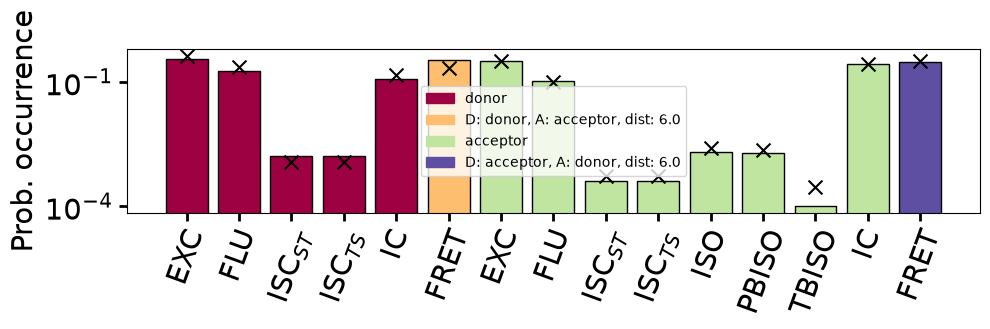

In [4]:
pair_prediction = pr.Prediction(coupled)
fig, ax = plt.subplots(figsize=(10, 3))
coupled_analysis.plot_frequency_transitions(prediction=pair_prediction, ax=ax)
fig.tight_layout()

### Limits of prediction for this interacting system

The plot above compares event frequencies, which Prediction can calculate
for this two-fluorophore model. It can also predict state-visit frequencies.
Once paired transitions are present, Prediction does not calculate state
occupations, state lifetimes, or transition waiting-time distributions.
The corresponding prediction attributes are None.

Analysis can measure these quantities from a simulated trajectory. The donor
S1 residence times in the earlier table came from Analysis, so they remain
available even though Prediction cannot provide a lifetime comparison for this
model. For three or more physical fluorophores, use simulation and Analysis;
Prediction is limited to at most two.

### How to read paired-event statistics

For example, a FRET event changes the pair from S1_S0 to S0_S1: the donor loses
its excitation and the acceptor gains it. This is one event, so it contributes
one FRET occurrence. Both molecules change state, so each also contributes a
state visit to its own statistics.

In the frequency plot, that FRET occurrence is normalized together with the
other events initiated by the molecule acting as donor. A paired bar is therefore
part of its donor's event-frequency total, not a fraction of all events in the
entire system. The reverse transfer is assigned to its own donor in the same way.

Paired-transition waiting times are likewise collected from the donor's event
and state history. State residence times, however, follow each molecule's actual
state changes: a paired event that leaves the acceptor unchanged does not end
its current residence. See
[Interpreting events and statistics](../../source/model_conventions.rst) for
the detailed counting conventions.

## Competing acceptors

Two acceptors share the name acceptor and the same data, so their single-state
kinetics and reported statistics are shared. Their different distances produce
different transfer rates. This system has three physical fluorophores and is
simulated directly; Prediction does not support more than two.

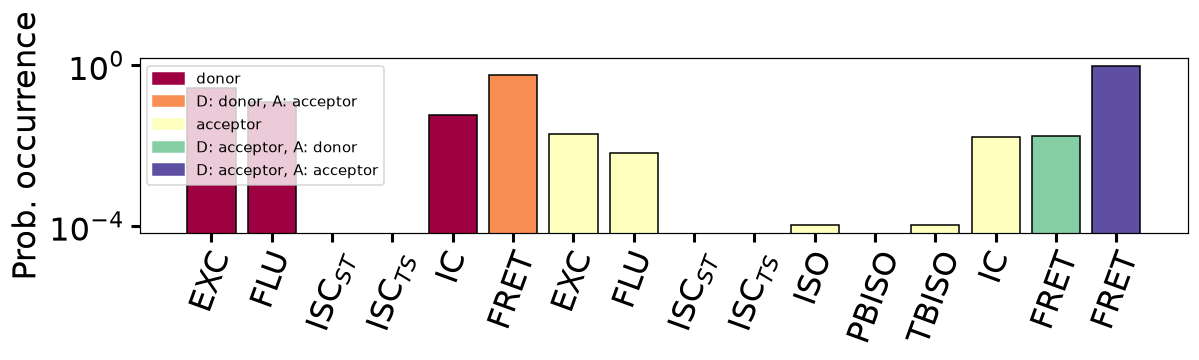

In [5]:
three_system = fl.FluorophoreSystem(
    [
        fl.Fluorophore("donor", [0, 0], constants=donor_data),
        fl.Fluorophore("acceptor", [6, 0], constants=acceptor_data),
        fl.Fluorophore("acceptor", [9, 0], constants=acceptor_data),
    ]
)
three_transitions = three_system.load_transitions(
    irradiance=2,
    wavelength=640,
    energy_transfer=True,
    bleaching=False,
    dstorm=False,
)
three_model = tr.TransitionSet(three_transitions, three_system).finalize()
three_simulation = si.Simulation(three_model)
three_simulation.run(start_at=(1, 0, 0), size=10_000, seed=23, warn_precision=False)
three_analysis = an.Analysis(three_simulation)
fig, ax = plt.subplots(figsize=(11, 3))
three_analysis.plot_frequency_transitions(diff_dist=False, ax=ax)
fig.tight_layout()

diff_dist=False combines matching transition types across distances for
plotting. To inspect actual competition, select a particular joint state.
Here the donor is excited and both acceptors are in S0. All positive-rate
outgoing processes contribute to the total rate K. The next waiting time
has mean 1/K, and each next-event probability is its rate divided by K.
These are conditional probabilities for this configuration, not overall
event fractions from the entire trajectory.

In [6]:
combined = three_model.combined_state_transitions_df
available = combined.loc[
    (combined["initial_state"] == (1, 0, 0)) & (combined["rate"] > 0),
    ["abbreviation", "fluorophore_ids", "final_state", "rate", "mechanism"],
].copy()
total_rate = available["rate"].sum()
available["next_event_probability"] = available["rate"] / total_rate
available

,abbreviation,fluorophore_ids,final_state,rate,mechanism,next_event_probability
id,,,,,,
16,FLU,[0],"(0, 0, 0)",2.000000e+08,NaN,0.143325
32,ISC_ST,[0],"(3, 0, 0)",1.000000e+06,NaN,0.000717
64,IC,[0],"(0, 0, 0)",1.323333e+08,NaN,0.094834
80,FRET,"[0, 1]","(0, 1, 0)",9.656829e+08,FRET,0.692034
84,FRET,"[0, 2]","(0, 0, 1)",8.477874e+07,FRET,0.060755
92,EXC,[1],"(1, 1, 0)",5.815700e+06,NaN,0.004168
104,EXC,[2],"(1, 0, 1)",5.815700e+06,NaN,0.004168


In [7]:
pd.Series({"total_outgoing_rate_per_s": total_rate, "mean_wait_ns": 1e9 / total_rate})

total_outgoing_rate_per_s    1.395426e+09
mean_wait_ns                 7.166269e-01
dtype: float64

## Optional: dense versus sparse storage

with_matrix_format() returns an equivalent TransitionSet with another matrix
representation. Sparse storage stores nonzero entries and their indices. It
can save matrix memory as systems grow; it does not avoid enumerating the
combined transitions or make every small model faster. The table compares
matrix-array storage only, not total process memory.

In [8]:
sparse_model = three_model.with_matrix_format("sparse").finalize()
dense_matrix = three_model.transition_matrix
sparse_matrix = sparse_model.transition_matrix
pd.DataFrame(
    {
        "format": ["dense", "sparse CSR"],
        "shape": [dense_matrix.shape, sparse_matrix.shape],
        "stored_bytes": [
            dense_matrix.nbytes,
            sparse_matrix.data.nbytes
            + sparse_matrix.indices.nbytes
            + sparse_matrix.indptr.nbytes,
        ],
    }
)

,format,shape,stored_bytes
0,dense,"(294, 294)",691488
1,sparse CSR,"(294, 294)",30520


In [9]:
dense_run = si.Simulation(three_model)
sparse_run = si.Simulation(sparse_model)
dense_run.run(size=2_000, seed=24, warn_precision=False)
sparse_run.run(size=2_000, seed=24, warn_precision=False)
pd.Series(
    {
        "equal_transition_probabilities": np.allclose(
            dense_matrix, sparse_matrix.toarray()
        ),
        "matching_event_sequence_in_this_run": np.array_equal(
            dense_run.transition_series, sparse_run.transition_series
        ),
        "matching_event_times_in_this_run": np.allclose(
            dense_run.time_series, sparse_run.time_series
        ),
    }
)

equal_transition_probabilities         True
matching_event_sequence_in_this_run    True
matching_event_times_in_this_run       True
dtype: bool

## Optional: paired mechanisms and variable orientation

A paired transition can represent any explicitly defined two-component
process. Here an effective contact-quenching event returns the excited donor
to S0 and leaves the acceptor in S0. Its manually supplied rate is illustrative.
The donor/acceptor fields identify the ordered components for bookkeeping,
even when those role names do not reflect reality.

kap_sq_var=True samples an orientation factor at each simulation step and
rescales only FRET transitions above minimum_rate. FRET rates must use the
reference κ² = 2/3. CONTACT keeps its supplied rate; its observed frequency
can still change because it competes with FRET. This mode uses a fixed event 
count and cannot be combined with end_time.

In [10]:
contact = tr.TransitionType(
    "CONTACT",
    tr.PairedState.S1_S0,
    tr.PairedState.S0_S0,
    photon=False,
    mechanism="CONTACT",
)
mixed_transitions = {key: list(items) for key, items in coupled.transitions.items()}
pair = (system.get_identity(donor), system.get_identity(acceptor))
distance = system.distances[pair]
key = f"D: {donor.name}, A: {acceptor.name}, dist: {distance}"
mixed_transitions[key].append(tr.Transition(contact, rate=1e7, fluorophore_ids=[pair]))
mixed_model = tr.TransitionSet(mixed_transitions, system).finalize()
variable_run = si.Simulation(mixed_model)
variable_run.run(
    size=2_000, kap_sq_var=True, minimum_rate=1e5, seed=25, warn_precision=False
)
mechanisms = mixed_model.combined_state_transitions_df[
    ["abbreviation", "mechanism", "rate"]
].drop_duplicates()
mechanisms["eligible_for_kappa_scaling"] = (
    mechanisms["mechanism"] == tr.TransitionMechanism.FRET
) & (mechanisms["rate"] > 1e5)
mechanisms

,abbreviation,mechanism,rate,eligible_for_kappa_scaling
id,,,,
0,EXC,NaN,3.577376e+06,False
4,FLU,NaN,2.000000e+08,False
8,ISC_ST,NaN,1.000000e+06,False
12,ISC_TS,NaN,1.000000e+05,False
16,IC,NaN,1.323333e+08,False
20,FRET,FRET,9.656829e+08,True
21,CONTACT,CONTACT,1.000000e+07,False
22,EXC,NaN,5.815700e+06,False
25,FLU,NaN,1.588235e+08,False


[Extending Fluopy](Tutorial_extending_fluopy.ipynb) demonstrates explicit PET
charge states and recombination. For self-transitions and paired events that
change either, both, or neither component, see
[Interpreting events and statistics](../../source/model_conventions.rst).
Next: [From emitted photons to measured signals](03_Detected_photons.ipynb).